# 03 · Evaluation and Testing

**Goal:** check how good the saved model is on fires it has never seen, then use it on new data.

- **Input:** `models/fire_risk_model.joblib`, `data/test/test_set.csv` (34 fires)
- **Output:** charts in `reports/figures/`, `reports/submission.csv`

## Setup

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, brier_score_loss, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
os.environ["PYTHONPATH"] = str(ROOT) + os.pathsep + os.environ.get("PYTHONPATH", "")

from src.data import censor_aware_labels, HORIZONS, ID_COL, TIME_COL, EVENT_COL, TARGET_COLS
from src.model import (competition_scores, hybrid_scorer, concordance_index, risk_band, RISK_BANDS)

DATA_DIR, FIG_DIR, REPORT_DIR = ROOT / "data", ROOT / "reports" / "figures", ROOT / "reports"
RANDOM_STATE = 42
H_COLORS = {12: "#E45756", 24: "#F2A541", 48: "#54A24B", 72: "#4C78A8"}
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name): fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=130)

bundle = joblib.load(ROOT / "models" / "fire_risk_model.joblib")
model, FEATURES, HEADLINE = bundle["model"], bundle["feature_columns"], bundle["headline_horizon"]
print({k: v for k, v in bundle.items() if k not in ("model", "feature_columns")})

{'horizons': [12, 24, 48, 72], 'headline_horizon': 48, 'model_family': 'RandomForest', 'label_mode': 'censor_aware', 'best_params': {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 5, 'n_estimators': 500}, 'cv_hybrid': 0.9756353350100282, 'cv_weighted_brier': 0.014516704864183067, 'cv_c_index': 0.952656761383188, 'n_train_rows': 187, 'sklearn_version': '1.9.1', 'random_state': 42}


## 1. Load the test data and predict
The first time we touch the test set.

In [2]:
test = pd.read_csv(DATA_DIR / "test" / "test_set.csv")
X_test, y_test = test[FEATURES], test[TARGET_COLS].to_numpy()
T, E = test[TIME_COL].to_numpy(), test[EVENT_COL].to_numpy()
Y = censor_aware_labels(T, E)
P = pd.DataFrame(model.predict_proba(X_test), columns=[f"p_{h}h" for h in HORIZONS])
assert (np.diff(P.to_numpy(), axis=1) >= -1e-12).all(), "probabilities must be non-decreasing in horizon"
pd.DataFrame({"positive": (Y == 1).sum(), "negative": (Y == 0).sum(), "excluded": Y.isna().sum()}).T

,hit_12h,hit_24h,hit_48h,hit_72h
positive,8,10,11,11
negative,25,17,13,0
excluded,1,7,10,23


## 2. Competition score
The test set is small (34 fires), so we also show a range (95% confidence interval) for each score.

In [3]:
official = competition_scores(P.to_numpy(), T, E)
rng = np.random.default_rng(RANDOM_STATE)
boot = []
for _ in range(2000):
    idx = rng.integers(0, len(test), len(test))
    if E[idx].sum() == 0: continue
    s = competition_scores(P.to_numpy()[idx], T[idx], E[idx])
    boot.append({k: s[k] for k in ("hybrid", "weighted_brier", "c_index", "brier_24h", "brier_48h", "brier_72h")})
boot = pd.DataFrame(boot)
summary = pd.DataFrame({"test": {k: official[k] for k in boot.columns},
                        "ci_low": boot.quantile(0.025), "ci_high": boot.quantile(0.975)})
summary.loc[["hybrid", "weighted_brier", "c_index"], "cv_dev"] = [bundle["cv_hybrid"], bundle["cv_weighted_brier"], bundle["cv_c_index"]]
summary.to_csv(REPORT_DIR / "test_metrics.csv")
print("C-index robustness (alternative urgency scores):",
      {f"p_{h}h": round(concordance_index(P[f"p_{h}h"], T, E), 4) for h in HORIZONS})
summary.round(4)

C-index robustness (alternative urgency scores): {'p_12h': 0.9329, 'p_24h': 0.9329, 'p_48h': 0.9329, 'p_72h': 0.9435}


,test,ci_low,ci_high,cv_dev
hybrid,0.9721,0.9432,0.9951,0.9756
weighted_brier,0.0126,0.0002,0.0387,0.0145
c_index,0.9364,0.8787,0.9877,0.9527
brier_24h,0.0383,0.0002,0.1261,NaN
brier_48h,0.0027,0.0001,0.0080,NaN
brier_72h,0.0000,0.0000,0.0000,NaN


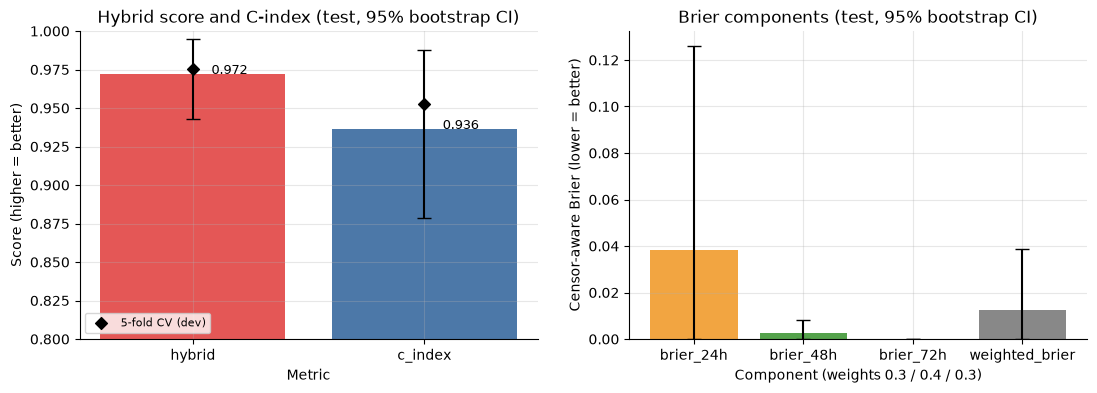

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
parts = ["hybrid", "c_index"]
axes[0].bar(parts, summary.loc[parts, "test"], yerr=[summary.loc[parts, "test"] - summary.loc[parts, "ci_low"], summary.loc[parts, "ci_high"] - summary.loc[parts, "test"]],
            capsize=5, color=["#E45756", "#4C78A8"])
axes[0].scatter(parts, summary.loc[parts, "cv_dev"], color="k", marker="D", zorder=3, label="5-fold CV (dev)")
for i, p in enumerate(parts): axes[0].text(i + .08, summary.loc[p, "test"], f"{summary.loc[p, 'test']:.3f}", fontsize=9)
axes[0].set_ylim(0.8, 1.0); axes[0].set_ylabel("Score (higher = better)"); axes[0].set_xlabel("Metric"); axes[0].set_title("Hybrid score and C-index (test, 95% bootstrap CI)"); axes[0].legend(fontsize=8)
bp = ["brier_24h", "brier_48h", "brier_72h", "weighted_brier"]
axes[1].bar(bp, summary.loc[bp, "test"], yerr=[summary.loc[bp, "test"] - summary.loc[bp, "ci_low"], summary.loc[bp, "ci_high"] - summary.loc[bp, "test"]],
            capsize=5, color=[H_COLORS[24], H_COLORS[48], H_COLORS[72], "#888888"])
axes[1].set_ylabel("Censor-aware Brier (lower = better)"); axes[1].set_xlabel("Component (weights 0.3 / 0.4 / 0.3)"); axes[1].set_title("Brier components (test, 95% bootstrap CI)")
save(fig, "03_competition_score"); plt.show()

## 3. Accuracy per time limit
A fire counts as "predicted hit" if its risk is 50% or more. At 72 h all fires are hits, so some numbers can't be computed there.

In [5]:
rows = []
for h in HORIZONS:
    keep = Y[f"hit_{h}h"].notna().to_numpy()
    y, p = Y.loc[keep, f"hit_{h}h"].astype(int).to_numpy(), P.loc[keep, f"p_{h}h"].to_numpy(); yhat = (p >= 0.5).astype(int)
    two = 0 < y.sum() < len(y)
    rows.append({"horizon": f"{h}h", "evaluable": int(keep.sum()), "positives": int(y.sum()),
                 "accuracy": accuracy_score(y, yhat), "precision": precision_score(y, yhat, zero_division=0) if two else np.nan,
                 "recall": recall_score(y, yhat), "f1": f1_score(y, yhat) if two else np.nan,
                 "roc_auc": roc_auc_score(y, p) if two else np.nan, "pr_auc": average_precision_score(y, p) if two else np.nan,
                 "brier": brier_score_loss(y, p, labels=[0, 1])})
cls_metrics = pd.DataFrame(rows).set_index("horizon")
cls_metrics.round(3)

,evaluable,positives,accuracy,precision,recall,f1,roc_auc,pr_auc,brier
horizon,,,,,,,,,
12h,33,8,0.879,0.750,0.75,0.750,0.975,0.929,0.054
24h,27,10,0.963,0.909,1.00,0.952,0.976,0.957,0.038
48h,24,11,1.000,1.000,1.00,1.000,1.000,1.000,0.003
72h,11,11,1.000,NaN,1.00,NaN,NaN,NaN,0.000


### Confusion matrices
Correct and wrong predictions per time limit.

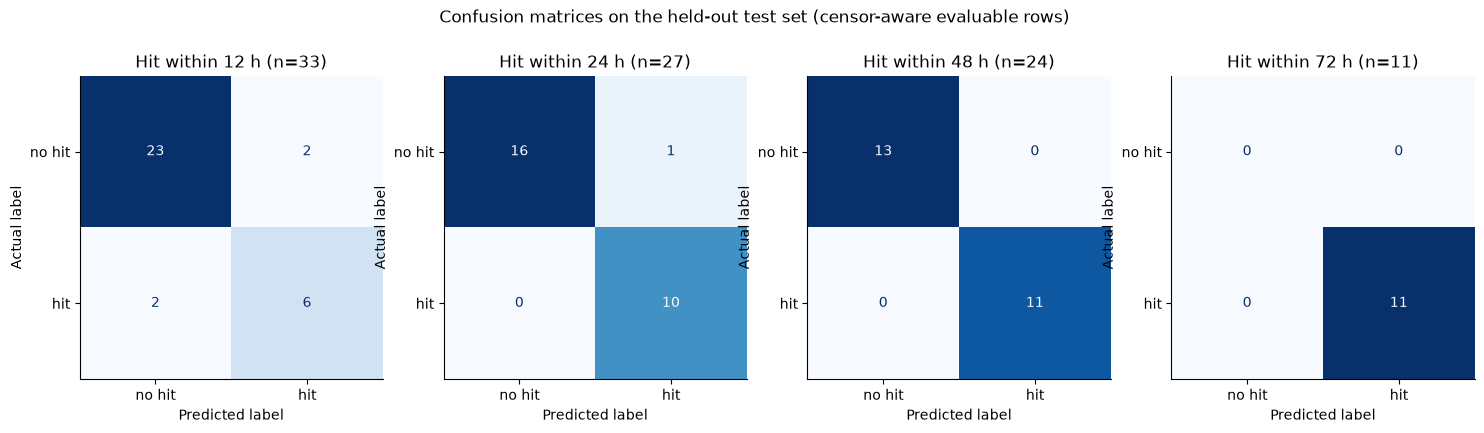

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, h in zip(axes, HORIZONS):
    keep = Y[f"hit_{h}h"].notna()
    cm = confusion_matrix(Y.loc[keep, f"hit_{h}h"].astype(int), (P.loc[keep, f"p_{h}h"] >= 0.5).astype(int), labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["no hit", "hit"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Hit within {h} h (n={keep.sum()})"); ax.set_xlabel("Predicted label"); ax.set_ylabel("Actual label"); ax.grid(False)
fig.suptitle("Confusion matrices on the held-out test set (censor-aware evaluable rows)", y=1.04)
save(fig, "03_confusion_matrices"); plt.show()

### ROC and precision-recall curves
The closer to the top-left (ROC) or top-right (PR), the better.

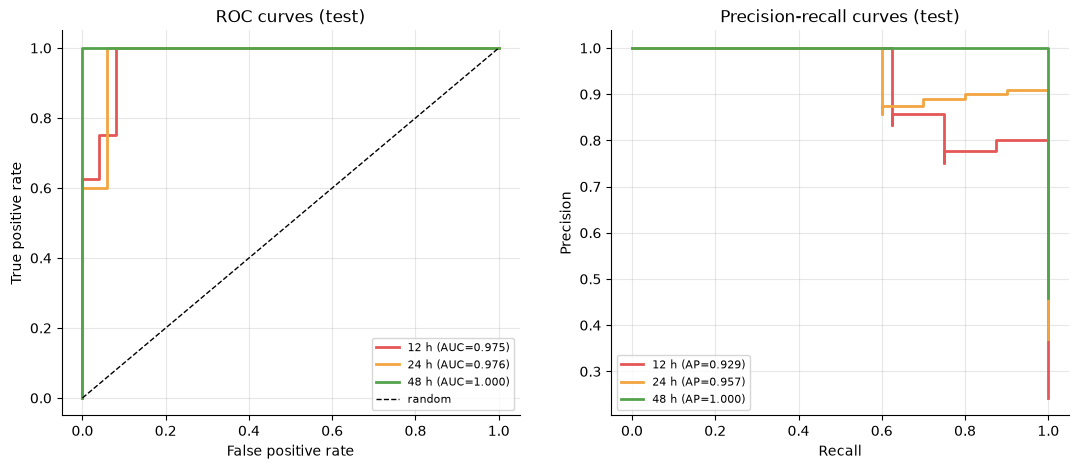

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for h in (12, 24, 48):
    keep = Y[f"hit_{h}h"].notna()
    y, p = Y.loc[keep, f"hit_{h}h"].astype(int), P.loc[keep, f"p_{h}h"]
    fpr, tpr, _ = roc_curve(y, p); axes[0].plot(fpr, tpr, color=H_COLORS[h], lw=2, label=f"{h} h (AUC={roc_auc_score(y, p):.3f})")
    prec, rec, _ = precision_recall_curve(y, p); axes[1].step(rec, prec, where="post", color=H_COLORS[h], lw=2, label=f"{h} h (AP={average_precision_score(y, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="random")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].set_title("ROC curves (test)")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-recall curves (test)")
axes[0].legend(fontsize=8, loc="lower right"); axes[1].legend(fontsize=8, loc="lower left")
save(fig, "03_roc_pr_curves"); plt.show()

## 4. Can we trust the percentages?
If the model says 30%, about 30% of those fires should really hit. Points on the dashed line = good. We also check on the training data (out-of-fold) because the test set is small.

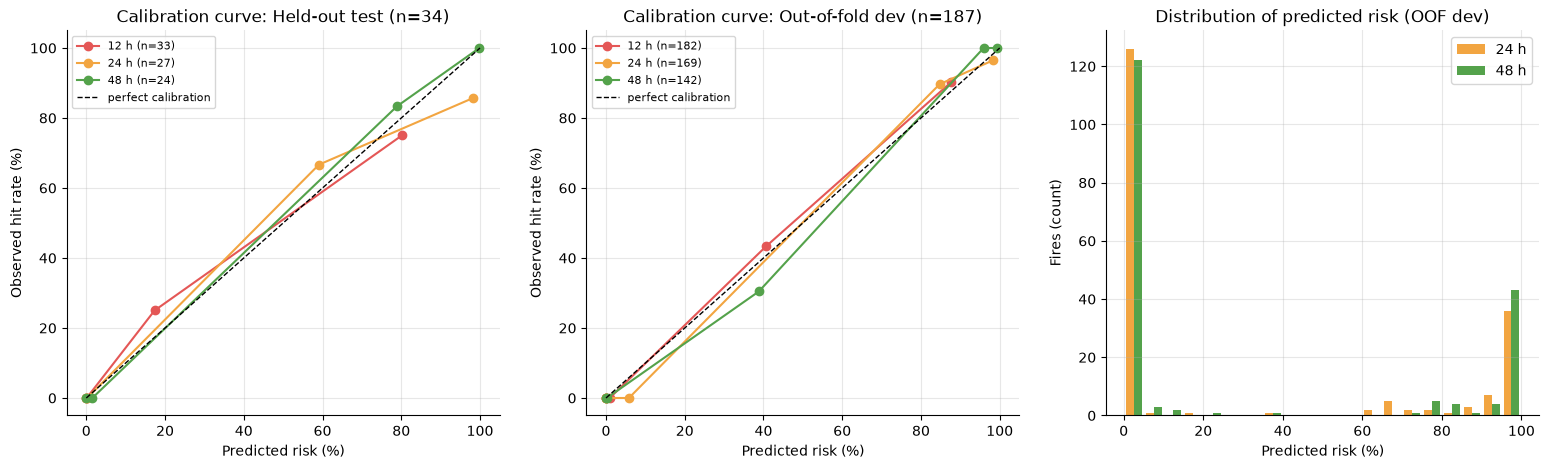

OOF dev competition scores: {'brier_12h': 0.0523, 'brier_24h': 0.0248, 'brier_48h': 0.0176, 'brier_72h': 0.0, 'weighted_brier': 0.0145, 'c_index': 0.9421, 'hybrid': 0.9725}
72 h prediction range (OOF): 0.979 to 1.0


In [8]:
dev = pd.read_csv(DATA_DIR / "processed" / "dev_set.csv")
Y_dev = censor_aware_labels(dev[TIME_COL], dev[EVENT_COL])
strata = (dev[EVENT_COL] + ((dev[EVENT_COL] == 1) & (dev[TIME_COL] <= 12))).to_numpy()
oof = np.zeros((len(dev), len(HORIZONS)))
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for tr, va in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(dev, strata):
        m = clone(model).fit(dev.loc[tr, FEATURES], dev.loc[tr, TARGET_COLS].to_numpy())
        oof[va] = m.predict_proba(dev.loc[va, FEATURES])
OOF = pd.DataFrame(oof, columns=[f"p_{h}h" for h in HORIZONS])
oof_scores = competition_scores(oof, dev[TIME_COL], dev[EVENT_COL])

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, (name, probs, labels, nb) in zip(axes[:2], [("Held-out test (n=34)", P, Y, 4), ("Out-of-fold dev (n=187)", OOF, Y_dev, 6)]):
    for h in (12, 24, 48):
        keep = labels[f"hit_{h}h"].notna()
        frac, mean_p = calibration_curve(labels.loc[keep, f"hit_{h}h"].astype(int), probs.loc[keep, f"p_{h}h"], n_bins=nb, strategy="quantile")
        ax.plot(mean_p * 100, frac * 100, "o-", color=H_COLORS[h], label=f"{h} h (n={keep.sum()})")
    ax.plot([0, 100], [0, 100], "k--", lw=1, label="perfect calibration")
    ax.set_xlabel("Predicted risk (%)"); ax.set_ylabel("Observed hit rate (%)"); ax.set_title(f"Calibration curve: {name}"); ax.legend(fontsize=8)
axes[2].hist([OOF["p_24h"] * 100, OOF["p_48h"] * 100], bins=20, color=[H_COLORS[24], H_COLORS[48]], label=["24 h", "48 h"])
axes[2].set_xlabel("Predicted risk (%)"); axes[2].set_ylabel("Fires (count)"); axes[2].set_title("Distribution of predicted risk (OOF dev)"); axes[2].legend()
save(fig, "03_calibration"); plt.show()
print("OOF dev competition scores:", {k: round(v, 4) for k, v in oof_scores.items() if not k.startswith("auc")})
print("72 h prediction range (OOF):", OOF["p_72h"].min().round(3), "to", OOF["p_72h"].max().round(3))

No 72 h line: every fire there is a hit, so the model just says about 98–100% for all of them.

### The hard part: *when* will a fire hit?
For fires that do hit, can the model tell early hits (≤ 12 h) from late ones?

    test: early-vs-late AUC among hits = 0.792  (hits=11, early=8, late=3)
 OOF dev: early-vs-late AUC among hits = 0.779  (hits=58, early=41, late=17)


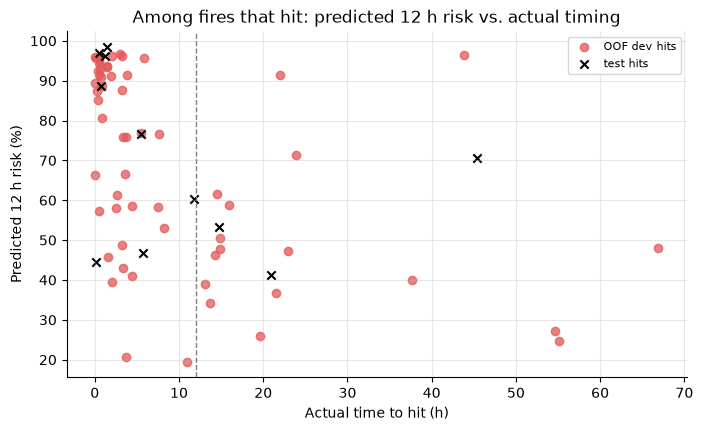

In [9]:
def timing_auc(probs, frame):
    hits = frame[EVENT_COL].to_numpy() == 1
    early = (frame.loc[hits, TIME_COL] <= 12).astype(int).to_numpy()
    return roc_auc_score(early, probs.loc[hits, "p_12h"]) if 0 < early.sum() < len(early) else np.nan, int(hits.sum()), int(early.sum())

for name, probs, frame in [("test", P, test), ("OOF dev", OOF, dev)]:
    auc, n_hits, n_early = timing_auc(probs, frame)
    print(f"{name:>8}: early-vs-late AUC among hits = {auc:.3f}  (hits={n_hits}, early={n_early}, late={n_hits - n_early})")

fig, ax = plt.subplots(figsize=(8, 4.5))
hits = dev[EVENT_COL] == 1
ax.scatter(dev.loc[hits, TIME_COL], OOF.loc[hits, "p_12h"] * 100, color=H_COLORS[12], alpha=.75, label="OOF dev hits")
th = test[EVENT_COL] == 1
ax.scatter(test.loc[th, TIME_COL], P.loc[th, "p_12h"] * 100, color="k", marker="x", label="test hits")
ax.axvline(12, color="grey", ls="--", lw=1); ax.set_xlabel("Actual time to hit (h)"); ax.set_ylabel("Predicted 12 h risk (%)")
ax.set_title("Among fires that hit: predicted 12 h risk vs. actual timing"); ax.legend(fontsize=8)
save(fig, "03_timing_among_hits"); plt.show()

## 5. Which features matter most?
Shuffle one feature at a time and see how much the score drops. Bigger drop = more important.

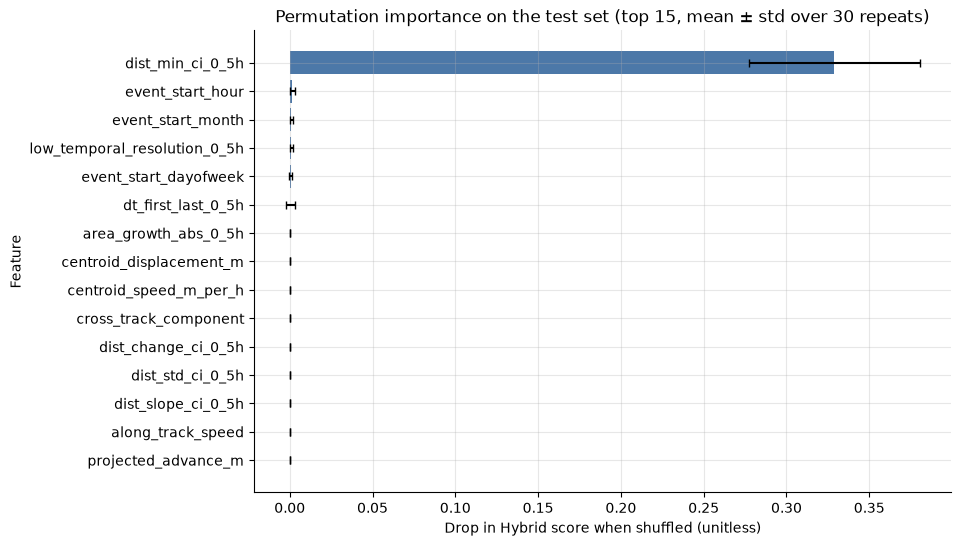

,importance,std
dist_min_ci_0_5h,0.3288,0.0516
event_start_hour,0.0016,0.0012
event_start_month,0.0009,0.0009
low_temporal_resolution_0_5h,0.0008,0.0009
event_start_dayofweek,0.0005,0.0006
dt_first_last_0_5h,0.0004,0.0029
area_growth_abs_0_5h,0.0000,0.0000
centroid_displacement_m,0.0000,0.0000
centroid_speed_m_per_h,0.0000,0.0000
cross_track_component,0.0000,0.0000


In [10]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    pi = permutation_importance(model, X_test, y_test, scoring=hybrid_scorer, n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"importance": pi.importances_mean, "std": pi.importances_std}, index=FEATURES).sort_values("importance")
top = imp.tail(15)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top["importance"], xerr=top["std"], color="#4C78A8", capsize=3)
ax.set_xlabel("Drop in Hybrid score when shuffled (unitless)"); ax.set_ylabel("Feature")
ax.set_title("Permutation importance on the test set (top 15, mean ± std over 30 repeats)")
save(fig, "03_permutation_importance"); plt.show()
imp.sort_values("importance", ascending=False).head(10).round(4)

## 6. Risk bands
Group predictions: **Low** (0–25%), **Medium** (25–50%), **High** (50–75%), **Critical** (75–100%), and check how many each group got right.

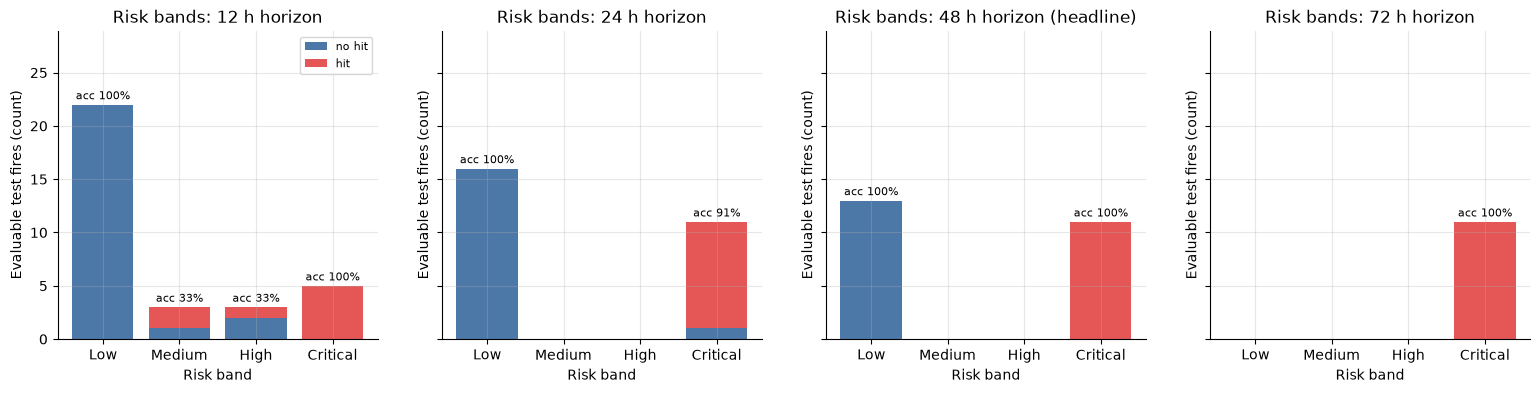

,horizon,band,fires,hits,mean_pred_%,observed_hit_%,band_accuracy_%
0,12h,Low,22,0,0.3,0.0,100.0
1,12h,Medium,3,2,44.2,66.7,33.3
2,12h,High,3,1,61.4,33.3,33.3
3,12h,Critical,5,5,91.4,100.0,100.0
4,24h,Low,16,0,0.1,0.0,100.0
5,24h,Medium,0,0,NaN,NaN,NaN
6,24h,High,0,0,NaN,NaN,NaN
7,24h,Critical,11,10,94.7,90.9,90.9
8,48h,Low,13,0,0.9,0.0,100.0
9,48h,Medium,0,0,NaN,NaN,NaN


In [11]:
band_rows = []
for h in HORIZONS:
    keep = Y[f"hit_{h}h"].notna().to_numpy()
    bands = risk_band(P[f"p_{h}h"] * 100).to_numpy()
    y = Y[f"hit_{h}h"].to_numpy()
    for b, _, _ in RISK_BANDS:
        m = keep & (bands == b)
        pred_hit = b in ("High", "Critical")
        band_rows.append({"horizon": f"{h}h", "band": b, "fires": int(m.sum()), "hits": int(np.nansum(y[m])),
                          "mean_pred_%": P.loc[m, f"p_{h}h"].mean() * 100 if m.any() else np.nan,
                          "observed_hit_%": y[m].mean() * 100 if m.any() else np.nan,
                          "band_accuracy_%": ((y[m] == int(pred_hit)).mean() * 100) if m.any() else np.nan})
band_table = pd.DataFrame(band_rows)

fig, axes = plt.subplots(1, 4, figsize=(19, 4), sharey=True)
for ax, h in zip(axes, HORIZONS):
    t = band_table[band_table.horizon == f"{h}h"].set_index("band")
    ax.bar(t.index, t["fires"] - t["hits"], color="#4C78A8", label="no hit"); ax.bar(t.index, t["hits"], bottom=t["fires"] - t["hits"], color="#E45756", label="hit")
    for i, b in enumerate(t.index):
        if t.loc[b, "fires"]: ax.text(i, t.loc[b, "fires"] + .5, f"acc {t.loc[b, 'band_accuracy_%']:.0f}%", ha="center", fontsize=8)
    ax.set_ylim(0, len(test) * 0.85); ax.set_title(f"Risk bands: {h} h horizon" + (" (headline)" if h == HEADLINE else ""))
    ax.set_xlabel("Risk band"); ax.set_ylabel("Evaluable test fires (count)")
axes[0].legend(fontsize=8)
save(fig, "03_risk_bands"); plt.show()
band_table.round(1)

Most fires are clearly Low or Critical. The few in Medium/High are the hard cases.

## 7. Try it on new fires
Take 8 fires from the competition file (no answers), save them as `data/test/sample_input.csv`, and run `src/predict.py` on them. `risk_percentage` = the 48 h risk.

In [12]:
new = pd.read_csv(DATA_DIR / "raw" / "test.csv")
near = new[new["dist_min_ci_0_5h"] <= 10_000].sample(4, random_state=RANDOM_STATE)
far = new[new["dist_min_ci_0_5h"] > 10_000].sample(4, random_state=RANDOM_STATE)
sample = pd.concat([near, far]).reset_index(drop=True)
assert not set(TARGET_COLS) & set(sample.columns)
sample.to_csv(DATA_DIR / "test" / "sample_input.csv", index=False)

cmd = [sys.executable, "src/predict.py", "--input", "data/test/sample_input.csv", "--output", "data/test/sample_predictions.csv"]
print("$ uv run python " + " ".join(cmd[1:]))
r = subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True); print(r.stdout or r.stderr)
assert r.returncode == 0
pred = pd.read_csv(DATA_DIR / "test" / "sample_predictions.csv")
pred[[ID_COL, "dist_min_ci_0_5h", "num_perimeters_0_5h"] + [f"risk_{h}h_pct" for h in HORIZONS] + ["risk_percentage", "risk_band"]]

$ uv run python src/predict.py --input data/test/sample_input.csv --output data/test/sample_predictions.csv


Wrote 8 predictions to data/test/sample_predictions.csv
 event_id  risk_percentage risk_band
 78227688             5.52       Low
 49502022             0.52       Low
 70283101            72.66      High
 50233410            99.55  Critical
 98446281             0.86       Low
 91234126             1.34       Low
 10662602             0.02       Low
 78173856             0.00       Low



,event_id,dist_min_ci_0_5h,num_perimeters_0_5h,risk_12h_pct,risk_24h_pct,risk_48h_pct,risk_72h_pct,risk_percentage,risk_band
0,78227688,5787.125811,1,0.54,0.62,5.52,98.37,5.52,Low
1,49502022,9816.867561,1,0.26,0.26,0.52,98.34,0.52,Low
2,70283101,1159.411207,2,53.04,63.29,72.66,99.38,72.66,High
3,50233410,4012.556331,1,76.27,98.47,99.55,99.86,99.55,Critical
4,98446281,102921.525969,2,0.25,0.25,0.86,98.34,0.86,Low
5,91234126,17895.570375,7,1.34,1.34,1.34,98.35,1.34,Low
6,10662602,116941.044708,1,0.02,0.02,0.02,98.33,0.02,Low
7,78173856,162285.394820,1,0.00,0.00,0.00,98.33,0.00,Low


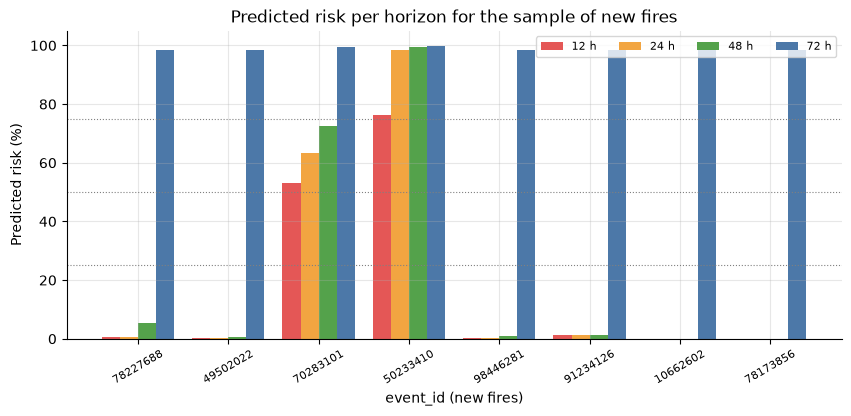

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(pred)); w = 0.2
for i, h in enumerate(HORIZONS):
    ax.bar(x + (i - 1.5) * w, pred[f"risk_{h}h_pct"], width=w, color=H_COLORS[h], label=f"{h} h")
for y0 in (25, 50, 75): ax.axhline(y0, color="grey", ls=":", lw=.8)
ax.set_xticks(x, pred[ID_COL].astype(str), rotation=30, fontsize=8)
ax.set_xlabel("event_id (new fires)"); ax.set_ylabel("Predicted risk (%)"); ax.set_ylim(0, 105)
ax.set_title("Predicted risk per horizon for the sample of new fires"); ax.legend(fontsize=8, ncol=4)
save(fig, "03_sample_predictions"); plt.show()

Predict all 95 competition fires and save the submission file.

In [14]:
cmd = [sys.executable, "src/predict.py", "--input", "data/raw/test.csv", "--output", "reports/test_predictions.csv", "--submission", "reports/submission.csv"]
r = subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True); assert r.returncode == 0, r.stderr
sub = pd.read_csv(REPORT_DIR / "submission.csv")
template = pd.read_csv(DATA_DIR / "raw" / "sample_submission.csv")
probs = sub[[c for c in sub.columns if c.startswith("prob_")]].to_numpy()
assert list(sub.columns) == list(template.columns) and set(sub[ID_COL]) == set(template[ID_COL])
assert ((probs >= 0) & (probs <= 1)).all() and (np.diff(probs, axis=1) >= -1e-12).all()
print("submission OK:", sub.shape, "| probabilities in [0, 1] and monotone")
print(pd.read_csv(REPORT_DIR / "test_predictions.csv")["risk_band"].value_counts().reindex([b for b, _, _ in RISK_BANDS]).fillna(0).astype(int).to_string())
sub.describe().round(3)

submission OK: (95, 5) | probabilities in [0, 1] and monotone
risk_band
Low         67
Medium       0
High         2
Critical    26


,event_id,prob_12h,prob_24h,prob_48h,prob_72h
count,9.500000e+01,95.000,95.000,95.000,95.000
mean,5.695393e+07,0.179,0.272,0.285,0.987
std,2.329721e+07,0.301,0.425,0.440,0.007
min,1.066260e+07,0.000,0.000,0.000,0.983
25%,4.027536e+07,0.000,0.000,0.000,0.983
50%,5.480111e+07,0.000,0.000,0.000,0.983
75%,7.536942e+07,0.375,0.786,0.934,0.995
max,9.964946e+07,0.992,0.998,1.000,1.000


## 8. Summary

| Score | Test result |
|---|---|
| **Hybrid score** | **0.972** (range 0.94–0.99) |
| C-index (ranking) | 0.936 |
| Brier (accuracy of %) | 0.013 |

**Good**
- The percentages are reliable (the calibration chart is on the line).
- Almost perfect at 48 h, the horizon that counts most.

**Not so good**
- Weaker at telling *when* a fire hits (early vs. late).
- The model depends almost only on distance.
- The 72 h value (~98% for all fires) is a scoring side effect. Use the 12/24/48 h values for decisions.

**Limits of the data**
- Only 221 fires in total.
- No weather, wind or terrain data.